# 04 — Phase 4 · Experiment 2 — Leave-One-Attack-Out (H2, Q1)

## Question
Which DDoS families generalise best to a family the model has never seen?

## Hypothesis H2
Generalisation depends on the held-out family: most mechanisms share enough
flow structure to be recognised, but Syn is the exception for the random forest.

## Protocol
For each of the 11 fine-grained attack families with at least 1,000 deduped
rows:
1. Purge the held-out family from **all 17 files**, not just the file named
   after it.  `UDPLag-training` contains Syn and UDP; `LDAP-training` contains
   NetBIOS; `MSSQL-training` contains LDAP; `UDP-training` contains MSSQL.
   Keeping any of those rows would make the "unseen" claim false.
2. Re-split the remaining rows with seeds 42, 43, 44.
3. Train binary Benign/DDoS on the remaining families.
4. Test on held-out family rows + a matched Benign sample from the known test
   fold.  The test set is balanced to keep Macro-F1 and FPR interpretable.
5. For seed 42, fit a lighter multiclass "known-family" model and predict the
   held-out rows to fill `confusion_to_matrix`: which known family does the
   unseen attack resemble?

Excluded by the 1,000-row rule: DrDoS_LDAP (993), Portmap (400), NetBIOS (374),
DrDoS_NetBIOS (311), WebDDoS (49).  This is a support constraint, not a claim
that these families are unimportant.

Results come from `uv run daf-projet exp2`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path.cwd()
if not (ROOT / "dataset").exists():
    ROOT = ROOT.parent
RES = ROOT / "results"
FIG = ROOT / "figures"

results = pd.read_csv(RES / "exp2.csv")
per_class = pd.read_csv(RES / "exp2_per_class.csv")
purge = pd.read_csv(RES / "exp2_purge_audit.csv")
conf_to = pd.read_csv(RES / "exp2_confusion_to.csv")

print(f"{results['family'].nunique()} families x {results['model'].nunique()} models x {results['seed'].nunique()} seeds = {len(results)} fits")
display(results.head())
display(purge.head(15))

11 families x 3 models x 3 seeds = 99 fits


,n_test,n_classes,macro_f1,weighted_f1,accuracy,pr_auc,roc_auc,fpr,fpr_at_tpr95,family,...,model_display,sklearn_version,n_family_available,n_test_heldout,n_test_benign,n_train,n_features_effective,fit_seconds,predict_seconds,recall_family
0,7204,2,0.433399,0.433399,0.498612,0.499307,0.498612,0.840644,0.950856,DrDoS_DNS,...,Dummy (stratified),1.9.1,3602,3602,3602,122125,65,0.149877,0.003842,0.837868
1,7204,2,0.965680,0.965680,0.965713,0.993339,0.992173,0.003054,0.013326,DrDoS_DNS,...,Logistic regression,1.9.1,3602,3602,3602,122125,65,1.137415,0.009247,0.934481
2,7204,2,0.965535,0.965535,0.965575,0.997297,0.997053,0.000555,0.002221,DrDoS_DNS,...,Random forest,1.9.1,3602,3602,3602,122125,65,6.145637,0.057928,0.931705
3,11588,2,0.435687,0.435687,0.500000,0.500000,0.500000,0.837591,0.950000,DrDoS_MSSQL,...,Dummy (stratified),1.9.1,5794,5794,5794,120372,65,0.150355,0.004751,0.837591
4,11588,2,0.998015,0.998015,0.998015,0.999969,0.999967,0.003279,0.000000,DrDoS_MSSQL,...,Logistic regression,1.9.1,5794,5794,5794,120372,65,1.440147,0.018955,0.999310


,family,src_file,rows
0,DrDoS_DNS,DNS-testing.parquet,3669
1,DrDoS_MSSQL,MSSQL-testing.parquet,5859
2,DrDoS_NTP,NTP-testing.parquet,121328
3,DrDoS_SNMP,SNMP-testing.parquet,2017
4,DrDoS_UDP,UDP-testing.parquet,10226
5,LDAP,LDAP-training.parquet,1097
6,LDAP,MSSQL-training.parquet,1
7,MSSQL,MSSQL-training.parquet,5884
8,MSSQL,UDP-training.parquet,41
9,Syn,Syn-testing.parquet,533


,family,model,macro_f1_mean,macro_f1_std,recall_family_mean,fpr_mean,pr_auc_mean
0,DrDoS_DNS,dummy,0.4354,0.0024,0.8314,0.8351,0.4991
1,DrDoS_DNS,logreg,0.9664,0.0006,0.9361,0.0033,0.9962
2,DrDoS_DNS,random_forest,0.9699,0.0042,0.9404,0.0006,0.9965
3,DrDoS_MSSQL,dummy,0.4361,0.0010,0.8320,0.8345,0.4994
4,DrDoS_MSSQL,logreg,0.9980,0.0001,0.9993,0.0033,0.9998
5,DrDoS_MSSQL,random_forest,0.9995,0.0001,0.9997,0.0006,0.9999
6,DrDoS_NTP,dummy,0.4475,0.0026,0.8090,0.8086,0.5001
7,DrDoS_NTP,logreg,0.9808,0.0142,0.9652,0.0037,0.9986
8,DrDoS_NTP,random_forest,0.9988,0.0002,0.9984,0.0009,0.9999
9,DrDoS_SNMP,dummy,0.4328,0.0081,0.8326,0.8390,0.4984


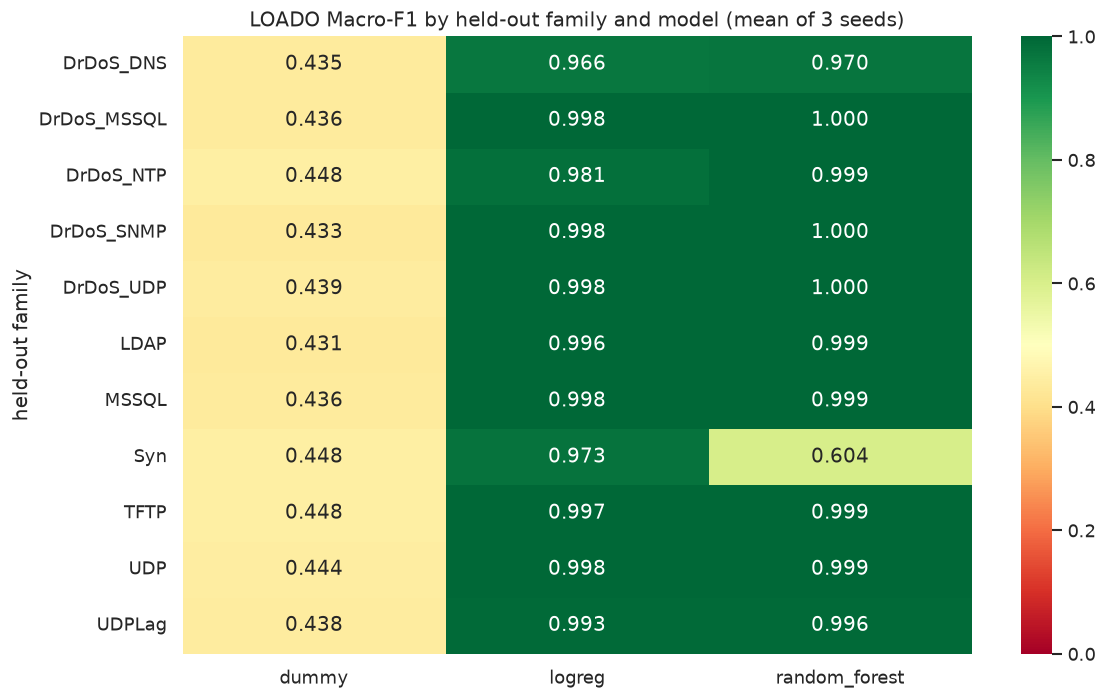

In [2]:
summary = (
    results.groupby(["family", "model"], observed=True)
    .agg(
        macro_f1_mean=("macro_f1", "mean"),
        macro_f1_std=("macro_f1", "std"),
        recall_family_mean=("recall_family", "mean"),
        fpr_mean=("fpr", "mean"),
        pr_auc_mean=("pr_auc", "mean"),
    )
    .reset_index()
)
display(summary.round(4))

fig, ax = plt.subplots(figsize=(10, 6))
pivot = summary.pivot(index="family", columns="model", values="macro_f1_mean")
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax)
ax.set_title("LOADO Macro-F1 by held-out family and model (mean of 3 seeds)")
ax.set_xlabel("")
ax.set_ylabel("held-out family")
fig.tight_layout()
fig.savefig(FIG / "04_exp2_family_model_heatmap.png", bbox_inches="tight")
plt.show()

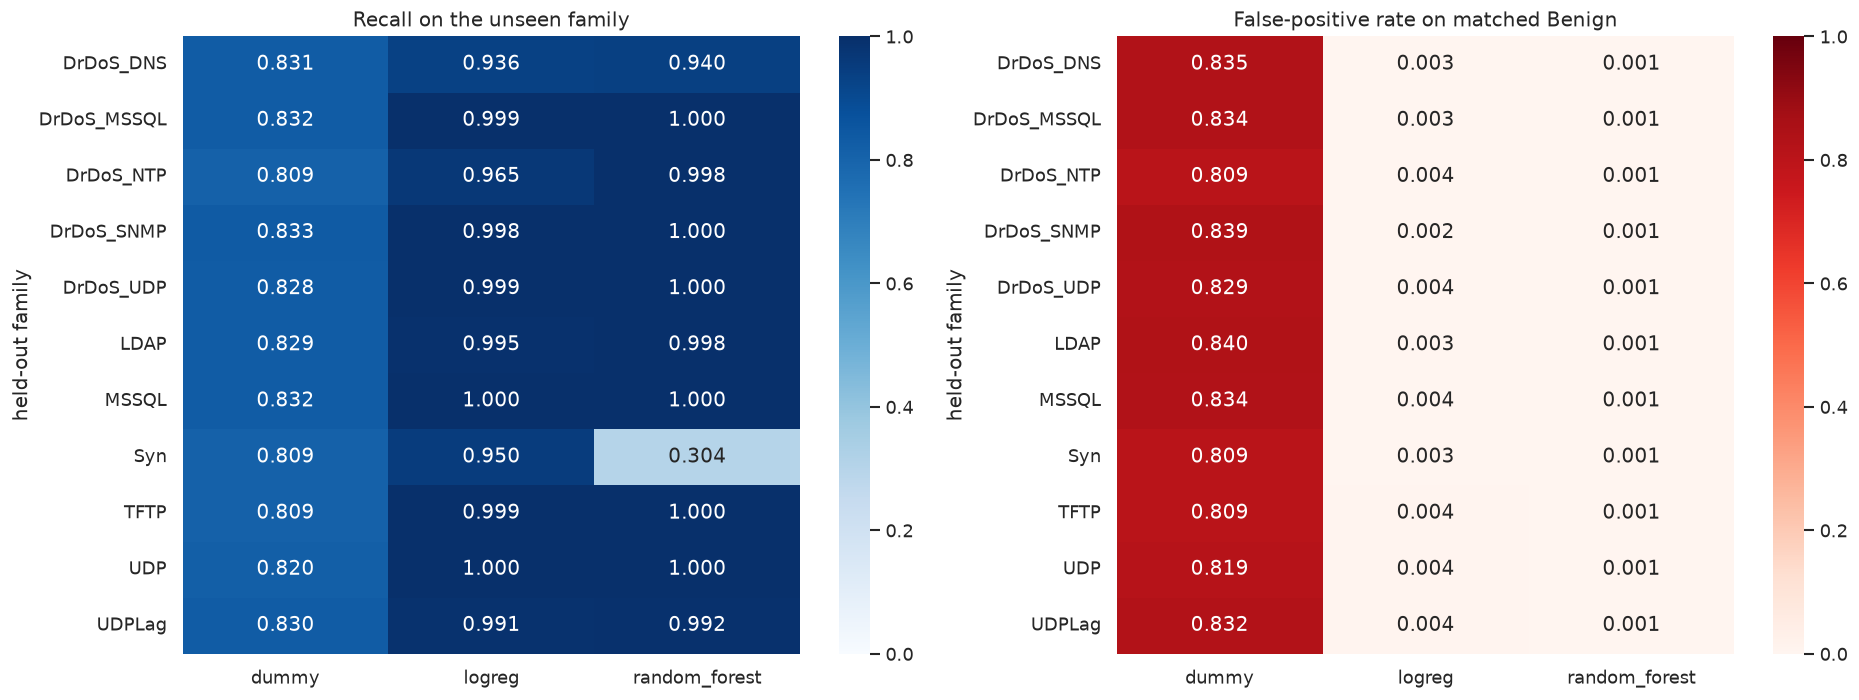

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, column, title in [
    (axes[0], "recall_family_mean", "Recall on the unseen family"),
    (axes[1], "fpr_mean", "False-positive rate on matched Benign"),
]:
    pivot = summary.pivot(index="family", columns="model", values=column)
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Blues" if column.startswith("recall") else "Reds", vmin=0, vmax=1, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("held-out family")
fig.tight_layout()
fig.savefig(FIG / "04_exp2_recall_fpr.png", bbox_inches="tight")
plt.show()

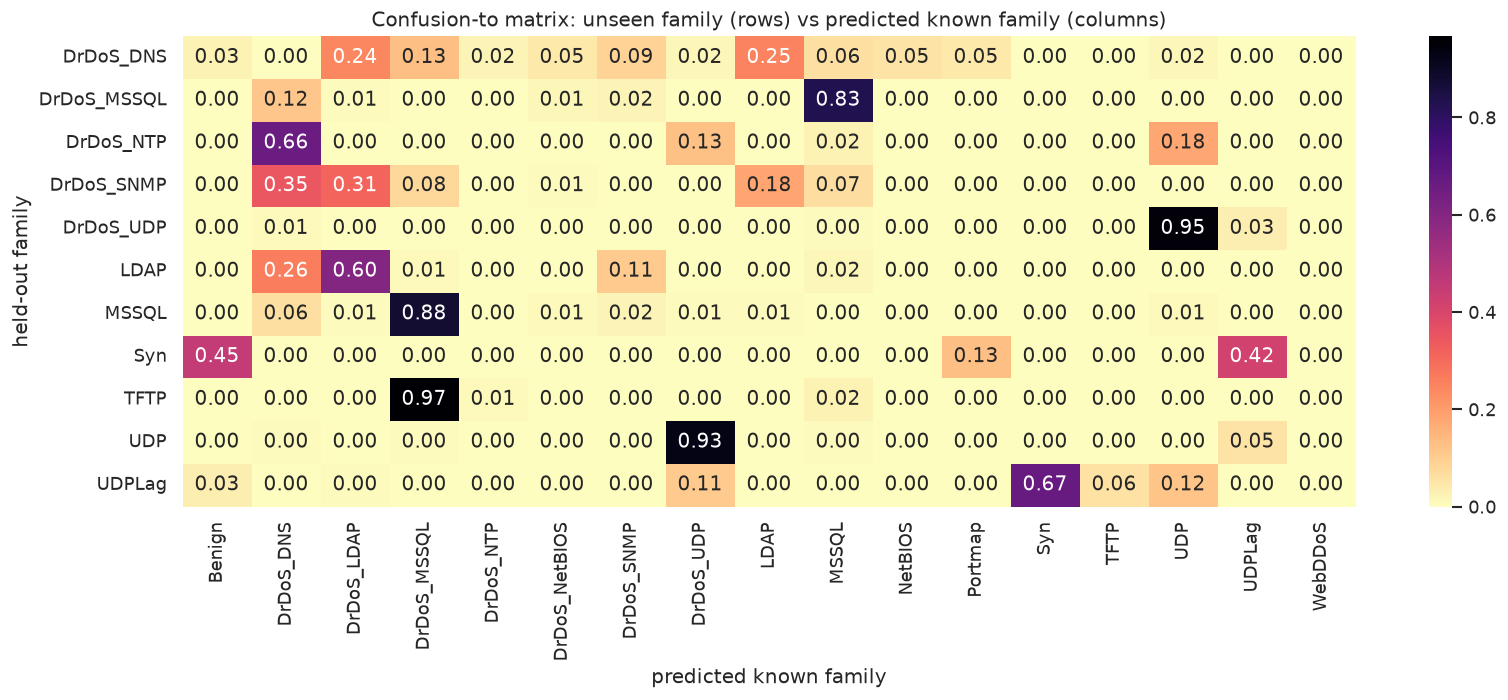

predicted_known_family,Benign,DrDoS_DNS,DrDoS_LDAP,DrDoS_MSSQL,DrDoS_NTP,DrDoS_NetBIOS,DrDoS_SNMP,DrDoS_UDP,LDAP,MSSQL,NetBIOS,Portmap,Syn,TFTP,UDP,UDPLag,WebDDoS
held_out_family,,,,,,,,,,,,,,,,,
DrDoS_DNS,0.026,0.000,0.242,0.131,0.020,0.045,0.089,0.017,0.250,0.061,0.053,0.045,0.000,0.001,0.016,0.003,0.001
DrDoS_MSSQL,0.001,0.115,0.007,0.000,0.000,0.013,0.020,0.002,0.003,0.834,0.000,0.002,0.000,0.000,0.003,0.000,0.000
DrDoS_NTP,0.003,0.663,0.000,0.001,0.000,0.000,0.000,0.126,0.000,0.025,0.000,0.000,0.000,0.000,0.180,0.001,0.002
DrDoS_SNMP,0.000,0.347,0.312,0.078,0.000,0.006,0.000,0.000,0.182,0.067,0.003,0.002,0.000,0.000,0.000,0.002,0.000
DrDoS_UDP,0.000,0.008,0.000,0.003,0.000,0.000,0.000,0.000,0.000,0.005,0.001,0.001,0.000,0.000,0.949,0.034,0.000
LDAP,0.002,0.262,0.603,0.008,0.000,0.000,0.108,0.000,0.000,0.016,0.000,0.001,0.000,0.000,0.000,0.001,0.000
MSSQL,0.001,0.060,0.007,0.877,0.002,0.011,0.019,0.006,0.006,0.000,0.000,0.003,0.000,0.001,0.009,0.000,0.000
Syn,0.451,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.130,0.000,0.000,0.000,0.418,0.000
TFTP,0.000,0.000,0.000,0.966,0.008,0.000,0.000,0.000,0.000,0.023,0.000,0.001,0.000,0.000,0.000,0.001,0.000


In [4]:
# Which known family is an unseen attack mistaken for?
matrix = (
    conf_to.groupby(["held_out_family", "predicted_known_family"], observed=True)["count"]
    .sum()
    .unstack(fill_value=0)
)
rates = matrix.div(matrix.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(rates, annot=True, fmt=".2f", cmap="magma_r", ax=ax)
ax.set_title("Confusion-to matrix: unseen family (rows) vs predicted known family (columns)")
ax.set_xlabel("predicted known family")
ax.set_ylabel("held-out family")
fig.tight_layout()
fig.savefig(FIG / "04_exp2_confusion_to.png", bbox_inches="tight")
plt.show()

display(rates.round(3))

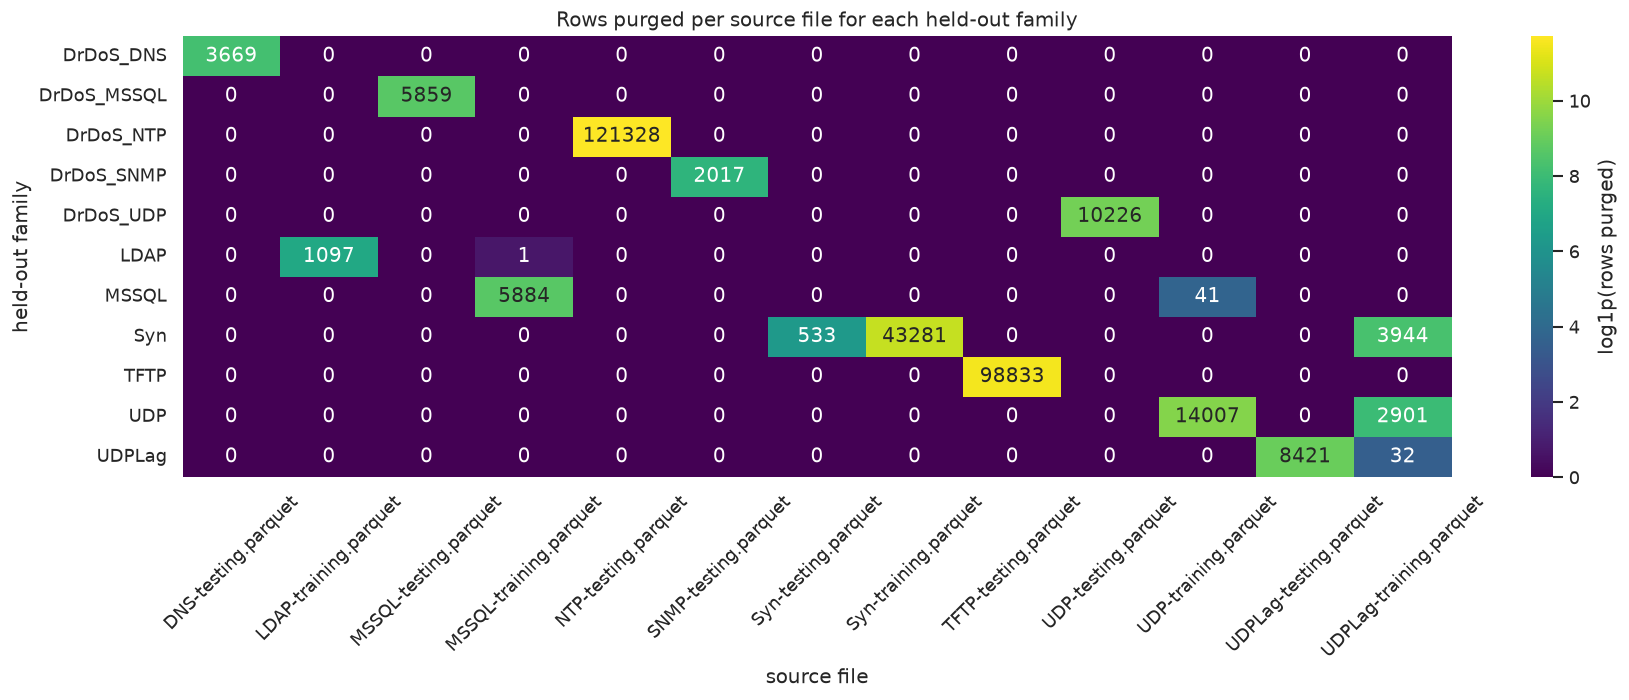

,source_files_containing_family
family,
Syn,3
MSSQL,2
UDP,2
UDPLag,2
LDAP,2
DrDoS_DNS,1
DrDoS_MSSQL,1
DrDoS_NTP,1
DrDoS_UDP,1


Syn appears in: ['Syn-testing.parquet', 'Syn-training.parquet', 'UDPLag-training.parquet']
UDP appears in: ['UDP-training.parquet', 'UDPLag-training.parquet']
LDAP appears in: ['LDAP-training.parquet', 'MSSQL-training.parquet']


In [5]:
# Purge audit: a family is not confined to the file named after it.
purge_matrix = purge.pivot_table(
    index="family", columns="src_file", values="rows", aggfunc="sum", fill_value=0
)
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(np.log1p(purge_matrix), annot=purge_matrix, fmt="d", cmap="viridis", cbar_kws={"label": "log1p(rows purged)"}, ax=ax)
ax.set_title("Rows purged per source file for each held-out family")
ax.set_xlabel("source file")
ax.set_ylabel("held-out family")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIG / "04_exp2_purge_audit.png", bbox_inches="tight")
plt.show()

files_per_family = (purge_matrix > 0).sum(axis=1).sort_values(ascending=False)
display(files_per_family.rename("source_files_containing_family").to_frame())
print("Syn appears in:", purge.loc[purge.family == 'Syn', 'src_file'].tolist())
print("UDP appears in:", purge.loc[purge.family == 'UDP', 'src_file'].tolist())
print("LDAP appears in:", purge.loc[purge.family == 'LDAP', 'src_file'].tolist())

,family,macro_f1_mean,macro_f1_std,recall_family_mean,fpr_mean,pr_auc_mean
23,Syn,0.6035,0.0212,0.3041,0.0010,0.9966
2,DrDoS_DNS,0.9699,0.0042,0.9404,0.0006,0.9965
32,UDPLag,0.9956,0.0004,0.9922,0.0010,0.9993
17,LDAP,0.9985,0.0005,0.9981,0.0010,0.9997
8,DrDoS_NTP,0.9988,0.0002,0.9984,0.0009,0.9999
26,TFTP,0.9992,0.0001,0.9997,0.0012,0.9998
5,DrDoS_MSSQL,0.9995,0.0001,0.9997,0.0006,0.9999
20,MSSQL,0.9995,0.0002,0.9998,0.0008,1.0000
14,DrDoS_UDP,0.9995,0.0002,0.9999,0.0008,1.0000
29,UDP,0.9993,0.0001,0.9999,0.0013,1.0000


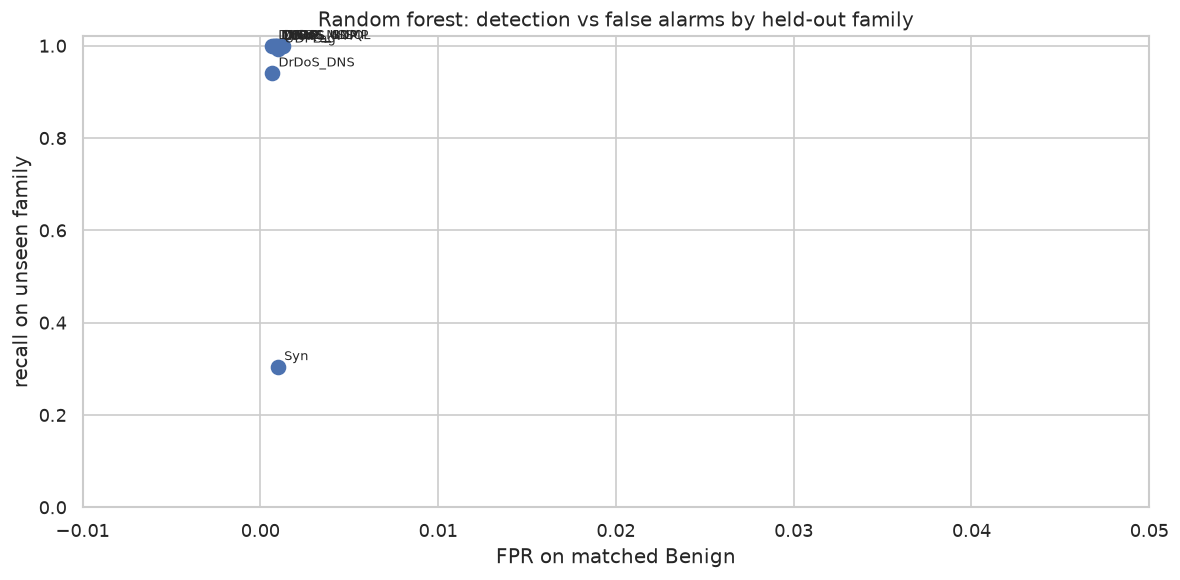

In [6]:
# Error profile: best and worst families for the strongest model, averaged over seeds.
rf = summary[summary["model"] == "random_forest"].sort_values("recall_family_mean")
display(rf[["family", "macro_f1_mean", "macro_f1_std", "recall_family_mean", "fpr_mean", "pr_auc_mean"]].round(4))

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(rf["fpr_mean"], rf["recall_family_mean"], s=70, color="#4c72b0")
for row in rf.itertuples():
    ax.annotate(row.family, (row.fpr_mean, row.recall_family_mean), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("FPR on matched Benign")
ax.set_ylabel("recall on unseen family")
ax.set_title("Random forest: detection vs false alarms by held-out family")
ax.set_xlim(-0.01, max(0.05, rf["fpr_mean"].max() * 1.1))
ax.set_ylim(0, 1.02)
fig.tight_layout()
fig.savefig(FIG / "04_exp2_recall_fpr_scatter.png", bbox_inches="tight")
plt.show()

## Verdict on H2 and answer to Q1

**Observation.** The heatmap is mostly high, but it is not flat.  For the
random forest, ten families remain above 0.96 (nine above 0.99), while
**Syn collapses to ≈ 0.604** (recall ≈ 0.30).  Logistic regression is much more
stable on Syn (≈ 0.973).  The confusion-to matrix explains the RF failure: Syn
rows are predicted as `Benign` (8,540), `UDPLag` (7,919) or `Portmap` (2,466),
not as one clear attack family.  The purge audit confirms that Syn also appears
in `UDPLag-training`, so purging only `Syn-training` would have leaked rows.

**Interprétation ML.** H2 is supported, but asymmetrically: the dependence on
the held-out family is real and concentrated on Syn, and it is model-dependent.
The RF learns a boundary that treats Syn-like flows as Benign/UDPLag, while the
linear model keeps a smoother boundary that still fires.  A single aggregate F1
would hide this failure; the per-family table and the confusion-to matrix expose
it.

**Interprétation cyber.** Q1 answer: most unseen families remain detectable, but
Syn is the exception for the RF.  The families that generalise best share a
header/window and rate profile with families seen in training; Syn's TCP
pattern is close enough to Benign/UDPLag for the RF to miss it.  For a SOC, the dangerous case is not a
wrong family label but a missed alarm: an unseen SYN flood could pass as benign.
The confusion-to matrix is more actionable than a single F1 because it says
which known behaviour the unseen traffic imitates.

**Limite.** Eleven rotations are not the whole space of unseen attacks; rare
families were excluded by support.  The matched Benign test is balanced, which
makes FPR comparable but not representative of the production base rate.  The
attribution model is a lighter random forest trained only for diagnosis, not the
headline detector.  Lab capture and three seeds limit external validity.  The
sibling check (`sibling` command) tests whether keeping `DrDoS_X` while holding
out `X` inflates the score; it is reported separately.